# Automatic Differentiation (AD)

This notebook covers:

1. **Forward mode from scratch:** a minimal `Dual` number type with overloaded operators, giving one directional derivative per pass.
2. **AD libraries in Julia:** ForwardDiff (forward mode) and Zygote (reverse mode). JVPs vs VJPs, and building a Jacobian by columns (n JVPs) or by rows (m VJPs).
3. **Nesting modes:** forward-over-reverse for Hessians and Hessian–vector products, and differentiating scalar functions of gradients.
4. **Implicit differentiation:** the derivative of a fixed point x = cos(p x) obtained from the implicit function theorem rather than by differentiating the iterations. This is a toy version of DFTK's polarizability calculation using ForwardDiff.


Running example: $f(x_1,x_2) = \log(x_1)+x_1x_2-\sin(x_2)$ at $x_0=(2,5)$. Taken from *Atılım et al (2018)*

## 1. Basics: Coding AD (Forward)

It is customary to use Dual numbers

In [14]:
struct Dual
    val
    der
end

### a) Overloading Operators

In [13]:
import Base: *, log, sin, cos, +, -

In [15]:
# The derivtive of a sum is the sum of derivatives.
+(a::Dual, b::Dual) = Dual(a.val + b.val, a.der + b.der)

+ (generic function with 191 methods)

In [16]:
# The derivtive of a substraction is the substraction of derivatives.
-(a::Dual, b::Dual) = Dual(a.val - b.val, a.der - b.der)

- (generic function with 195 methods)

In [17]:
# The derivative of a product is the product of derivatives 
*(a::Dual, b::Dual) = Dual(a.val * b.val, a.der*b.val + a.val*b.der)

* (generic function with 193 methods)

In [28]:
# The derivative of a sin(a) is cos(a.val)*a.der
sin(a::Dual) = Dual(sin(a.val), cos(a.val)*a.der)

sin (generic function with 14 methods)

In [19]:
# The derivative of log is der/var
log(a::Dual) = Dual(log(a.val), a.der/a.val)

log (generic function with 26 methods)

### b) Example I: Partial derivative with respect to x_1

In [20]:
f(x1, x2) = log(x1) + x1 * x2 - sin(x2)

f (generic function with 1 method)

In [21]:
y = f(Dual(2.0, 1.0), Dual(5.0, 0.0))

Dual(11.652071455223084, 5.5)

Which is

In [23]:
f(2,5)

11.652071455223084

and $\nabla f(x_0)\cdot v = \frac{\partial f}{\partial x_1}\big|_{x_0}v_1= [v_1/x_1 +x_2*v_1]\big|_{x_0}$ with $x_0=(2,5)$ and $v=(1,0)$

In [24]:
1/2+5*1

5.5

### c) Example II:  Partial derivative with respect to x_2

In [34]:
z = f(Dual(2.0, 0.0), Dual(5.0, 1.0))

Dual(11.652071455223084, 1.7163378145367738)

#### Notes:
- The output of the functions are `Dual`, then all operations should be defined among them
- To compute the "derivative", do chain rule on the argument of the function

## 2. Libraries: AD in Julia

In [35]:
using ForwardDiff

### a) Example above using ForwardDiff Library

ForwardDiff’s main functions take a single argument. Here we compute the full gradient

In [120]:
g(x) = f(x[1], x[2])

ForwardDiff.gradient(g, [2.0, 5.0])

2-element Vector{Float64}:
 5.5
 1.7163378145367738

Or we can use the same structure as our implementation but using ForwardDiff:

In [122]:
y = f(ForwardDiff.Dual(2.0, 1.0), ForwardDiff.Dual(5.0, 0.0))

ForwardDiff.value(y),   ForwardDiff.partials(y)      

(11.652071455223084, Partials(5.5,))

In [49]:
y = f(ForwardDiff.Dual(2.0, 0.0), ForwardDiff.Dual(5.0, 1.0))
ForwardDiff.value(y),   ForwardDiff.partials(y)      

(11.652071455223084, Partials(1.7163378145367738,))

### b) Reverse mode with Zygote


In [52]:
using Zygote

In [54]:
Zygote.gradient(g, [2.0, 5.0])  

([5.5, 1.7163378145367738],)

### c) JVP vs VJP

Let us define a vector-valued function $F$

In [55]:
F(x) = [sin(x[1]) + x[1]*x[2],
        x[2]*x[3] + log(x[3])]

F (generic function with 1 method)

The Jacobian-vector product (JVP) is what we have done in *forward mode*. For example, in our defined forward AD. The product $J_f\big|_{x_0} v$ is computed as

In [68]:
x0=(2.0, 3.0, 4.0)
v=(1.0, 1.0, 1.0)

F([Dual(x0[1],v[1]),Dual(x0[2],v[2]), Dual(x0[3],v[3])])

2-element Vector{Dual}:
 Dual(6.909297426825682, 4.583853163452858)
 Dual(13.38629436111989, 7.25)

with the evaluation of $F(x_0)$ given by the first values of each `Dual` and the second values are 

- $v_1 * \partial F_1\ \partial x_1 + v_2*\partial F_1/ \partial x_2 + v_3 * \partial F_1 / \ \partial x_3$ and $v_1 * \partial F_2\ \partial x_1 + v_2*\partial F_2/ \partial x_2 + v_3 * \partial F_2 / \ \partial x_3$
- or equivalently $\nabla F_1 \cdot v$ and $\nabla F_2 \cdot v$
- or equivalently the JVP $J_F v$

Using ForwardDiff this can be done with

In [70]:
ForwardDiff.derivative(t -> F(x0 .+ t .* v), 0.0) 

2-element Vector{Float64}:
 4.583853163452858
 7.25

or

In [73]:
y = F(ForwardDiff.Dual.(x0, v))   # seed each x_i with v_i

ForwardDiff.value.(y),first.(ForwardDiff.partials.(y))            # J·v

([6.909297426825682, 13.38629436111989], [4.583853163452858, 7.25])

The vector-Jacobian product (VJP), $v^TJ$ is what is done by pullback + back(v) in Zygote. Entry by entry it is equivalent to $J^T v$, however one is the transpose of the other. If the result is a plain vector, Julia do not distinguish them

In [86]:
y, back = Zygote.pullback(F, x0);
back([1.0, 1.0])

((2.5838531634528574, 6.0, 3.25),)

In [87]:
back([2.0, 1.0])[1] 

(5.167706326905715, 8.0, 3.25)

### d ) Jacobians from JVP and VJP

We can form the Jacobian column by column with forward mode and $n$ JVPs, using the $n$ canonical vectors

In [82]:
e1=[1,0,0]
col1 = ForwardDiff.derivative(t -> F(x0 .+ t .* e1), 0.0) 

2-element Vector{Float64}:
 2.5838531634528574
 0.0

In [83]:
e2=[0,1,0]
col2 = ForwardDiff.derivative(t -> F(x0 .+ t .* e2), 0.0) 

2-element Vector{Float64}:
 2.0
 4.0

In [84]:
e3=[0,0,1]
col3 = ForwardDiff.derivative(t -> F(x0 .+ t .* e3), 0.0) 

2-element Vector{Float64}:
 0.0
 3.25

The the Jacobian of F at point x0 is

In [85]:
J_fwd = [col1 col2 col3]

2×3 Matrix{Float64}:
 2.58385  2.0  0.0
 0.0      4.0  3.25

Constructing the Jacobian by rows with reverse mode and $m$ VJPs, using $m$ canonical vectors

In [93]:
y, back = Zygote.pullback(F, x0);
row1=back([1.0,0.0])

((2.5838531634528574, 2.0, 0.0),)

In [94]:
row2=back([0.0,1.0])

((0.0, 4.0, 3.25),)

In [95]:
J_rev = [row1; row2]

2-element Vector{Tuple{Tuple{Float64, Float64, Float64}}}:
 ((2.5838531634528574, 2.0, 0.0),)
 ((0.0, 4.0, 3.25),)

And we can see that they coincide and they do coincide with the analytical Jacobian evaluated at x0.

## 3. Forward-over-reverse mode

In Forward-over-reverse we perform a forward AD mode, for example to compute the gradient of a scalar function, and afterwards we perform a forward AD to compute for example the derivative of the gradient, i.e. the Hessian of the original function

### a) Hessian

The idea is, having $f:R^n\to R$, we can cheaply compute the function $\nabla f:R^n\to R^n$ evaluated at a certain point in the domain $x_0$ using one application of backward AD mode. Then we can use the forward AD mode, with the function $\nabla f$, as if it is any other function. The to compute the Hessian of f, we need to compute the Jacobian of $\nabla f$ as we have done before.

With Zygote and ForwardDiff:

In [103]:
x0 = [2.0, 5.0]

# 1. reverse mode: gradient as a function
∇g(x) = Zygote.gradient(g, x)[1]

# 2. forward mode on top: Hessian–vector product
hvp(x, v) = ForwardDiff.derivative(t -> ∇g(x .+ t .* v), 0.0)

# 3. columns from the canonical vectors
H = hcat(hvp(x0, [1.0, 0.0]), hvp(x0, [0.0, 1.0]))

2×2 Matrix{Float64}:
 -0.25   1.0
  1.0   -0.958924

or directly with ForwardDiff

In [131]:
H = ForwardDiff.jacobian(∇g, x0)

2×2 Matrix{Float64}:
 -0.25   1.0
  1.0   -0.958924

### b) Hessian vector product

Instead of using the canonical vectors to extract the columns of the Hessian, we can use an abitrary vector to obtain the Hessian-vector prduct (HVP) evaluated at $x_0$

In [129]:
v = [1.0, 1.0]
hvp(x0, v)        

2-element Vector{Float64}:
 0.75
 0.041075725336861546

In [130]:
H * v

2-element Vector{Float64}:
 0.75
 0.041075725336861546

### c) Scalar-valued functions of gradients

In [108]:
using LinearAlgebra

fn(x) = 1 / norm(x)         
gn(z) = sum(z)^3
∇fn(x) = Zygote.gradient(fn, x)[1]

hn(x) = gn(∇fn(x))          

function ∇hn(x)
    z = ∇fn(x)                                          # 1. reverse
    u = Zygote.gradient(gn, z)[1]                       # 2. reverse
    return ForwardDiff.derivative(α -> ∇fn(x .+ α .* u), 0.0)   # 3. forward over reverse
end

x = [1.0, 2.0, 3.0]
∇hn(x)

3-element Vector{Float64}:
 0.00021467405044432297
 0.0011807072774437752
 0.002146740504443228

## 4. Example using implicit derivative

We exemplify one use of ForwardDiff similar in spirit to the application to compute polarizability in DFTK (https://docs.dftk.org/v0.4.2/examples/forwarddiff/).

In this example we define the $x(p)$ as the solution of the equation $x=\cos(px)$ and we want to know how $dx/dp$ looks like

We need to solve this equation by a fixed-point method

In [137]:
function fixpoint(p; x=0.5, tol=1e-12)
    for _ in 1:1000
        xn = cos(p*x)
        abs(xn - x) < tol && return xn
        x = xn
    end
    x
end

fixpoint (generic function with 1 method)

The solution for $p=1$ is

In [149]:
p = 1.0
xs = fixpoint(p)

0.739085133215467

We could, find the value of $dx/dp\big|_{p=1}$ by performing the whole fixed point method with Duals, usign ForwardDiff

In [150]:
dx_unrolled = ForwardDiff.derivative(fixpoint, p)

-0.29747434147880847

This would be expensive for a complex fixpoint method, as the one encounter using DFT. So we can instead reformulate the problem as a root $g(x,p) = x-\cos(p*x)=0$, so $dg/dp=\partial g/\partial x d x/d p + \partial g/\partial p=0$ and then $d x/d p = - (\partial g/\partial p) / (\partial g/\partial x) $, and we can use AD to compute this derivatives, with a single converge solution (instead of carrying the Duals in the though the fixed point method)

In [153]:
g(x, p) = x - cos(p*x)

gx = ForwardDiff.derivative(x -> g(x, p), xs)     # ∂g/∂x at (xs, p)
gp = ForwardDiff.derivative(q -> g(xs, q), p)     # ∂g/∂p at (xs, p)

0.49785663632458466

In [154]:
dx_implicit = -gp / gx

-0.2974743415100153

We can wrap all this to plot the derivative

In [163]:
using Plots

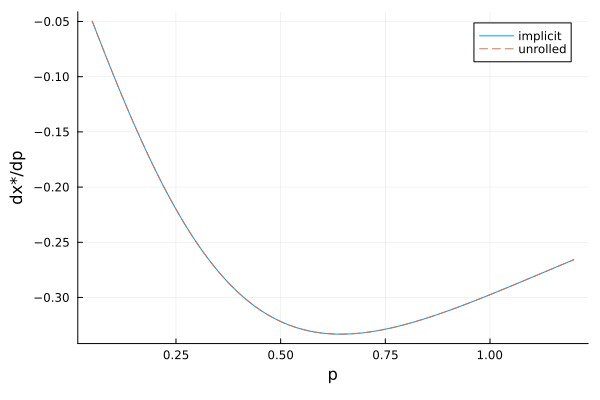

In [164]:
res(x, p) = x - cos(p*x)

function dxdp(p)
    xs = fixpoint(p)                                  # x*(p)
    gx = ForwardDiff.derivative(x -> res(x, p), xs)   # ∂res/∂x at (x*, p)
    gp = ForwardDiff.derivative(q -> res(xs, q), p)   # ∂res/∂p at (x*, p)
    return -gp / gx
end

ps = 0.05:0.01:1.2
plot(ps, dxdp.(ps), label="implicit", xlabel="p", ylabel="dx*/dp")
plot!(ps, [ForwardDiff.derivative(fixpoint, p) for p in ps], ls=:dash, label="unrolled")